In [2]:
import requests
import pandas as pd
import numpy as np

days = 365
btc_url = f"https://api.coingecko.com/api/v3/coins/bitcoin/market_chart?vs_currency=usd&days={days}&interval=daily"
eth_url = f"https://api.coingecko.com/api/v3/coins/ethereum/market_chart?vs_currency=usd&days={days}&interval=daily"

btc_json = requests.get(btc_url).json()
eth_json = requests.get(eth_url).json()

In [3]:
#Convert to Pandas DataFrame and merge

btc = pd.DataFrame(btc_json["prices"], columns=["timestamp", "btc_price"])
eth = pd.DataFrame(eth_json["prices"], columns=["timestamp", "eth_price"])

btc["date"] = pd.to_datetime(btc["timestamp"], unit="ms").dt.date
eth["date"] = pd.to_datetime(eth["timestamp"], unit="ms").dt.date

df = pd.merge(
    btc[["date", "btc_price"]],
    eth[["date", "eth_price"]],
    on="date",
    how="inner"
).sort_values("date").reset_index(drop=True)

print(df.head())

len(df)

         date     btc_price    eth_price
0  2025-04-25  93872.814229  1769.392511
1  2025-04-26  94773.112006  1788.798180
2  2025-04-27  94644.066371  1821.269530
3  2025-04-28  93809.337820  1793.691844
4  2025-04-29  95030.606455  1799.501914


368

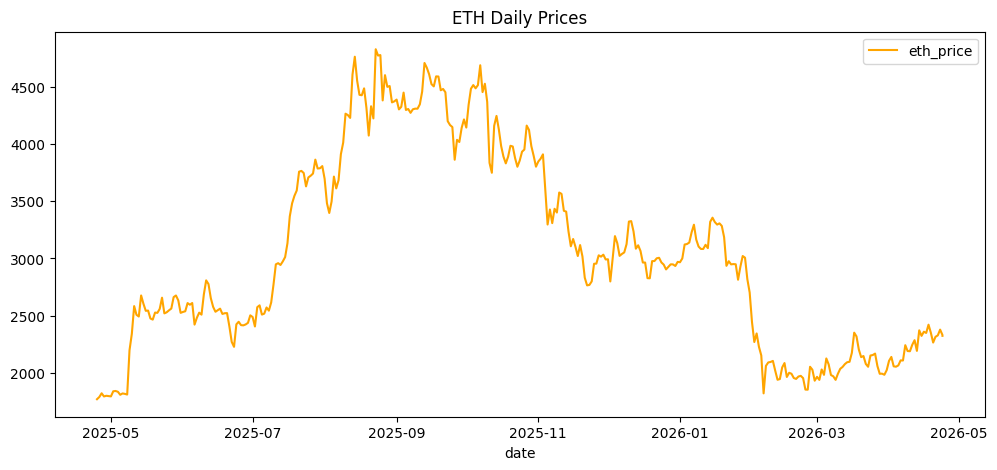

In [4]:
import matplotlib.pyplot as plt

df.plot(x="date", y=["eth_price"], figsize=(12, 5), title="ETH Daily Prices", color=["orange"])
plt.show()

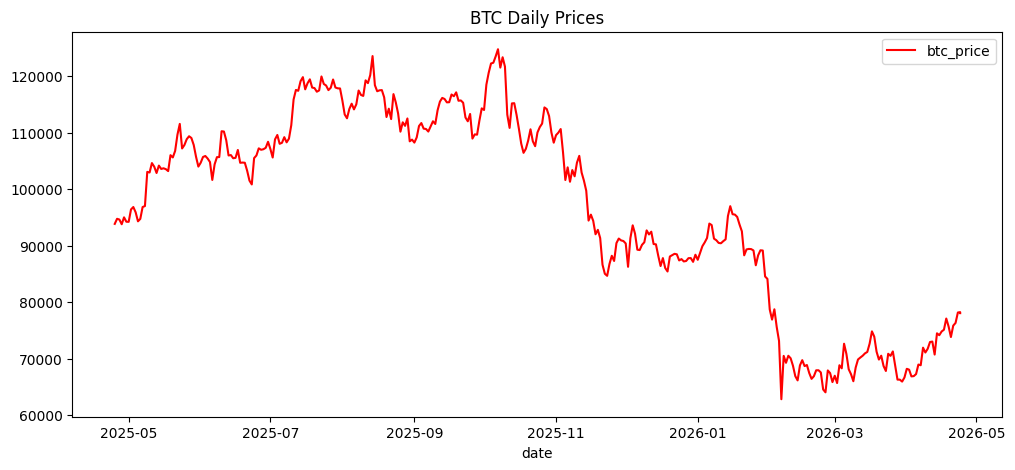

In [5]:
df.plot(x="date", y=["btc_price"], figsize=(12, 5), title="BTC Daily Prices" ,color = ["red"])
plt.show()

In [6]:
pip install statsmodels

Note: you may need to restart the kernel to use updated packages.


In [7]:
#ADF test for stationarity drop NaNs, then forward-fill any remaining gaps 
from statsmodels.tsa.stattools import adfuller

def adf_report(series, name):
  
    filled_series = series.ffill()
    result = adfuller(filled_series)  # Drop any remaining leading NaNs
    print(f"{name}")
    print(f"ADF statistic: {result[0]:.4f}")
    print(f"p-value: {result[1]:.4f}")
    print(f"Used lags: {result[2]}")
    print(f"Observations: {result[3]}")
    print("-" * 40)

adf_report(df["btc_price"], "BTC price")
adf_report(df["eth_price"], "ETH price")

BTC price
ADF statistic: -0.8462
p-value: 0.8052
Used lags: 0
Observations: 367
----------------------------------------
ETH price
ADF statistic: -1.5948
p-value: 0.4862
Used lags: 0
Observations: 367
----------------------------------------


In [8]:
#Make stationary by taking log returns
df["btc_ret"] = np.log(df["btc_price"]).diff()
df["eth_ret"] = np.log(df["eth_price"]).diff()

df = df.dropna().reset_index(drop=True)

adf_report(df["btc_ret"], "BTC log returns")
adf_report(df["eth_ret"], "ETH log returns")

BTC log returns
ADF statistic: -20.2635
p-value: 0.0000
Used lags: 0
Observations: 366
----------------------------------------
ETH log returns
ADF statistic: -13.7545
p-value: 0.0000
Used lags: 1
Observations: 365
----------------------------------------


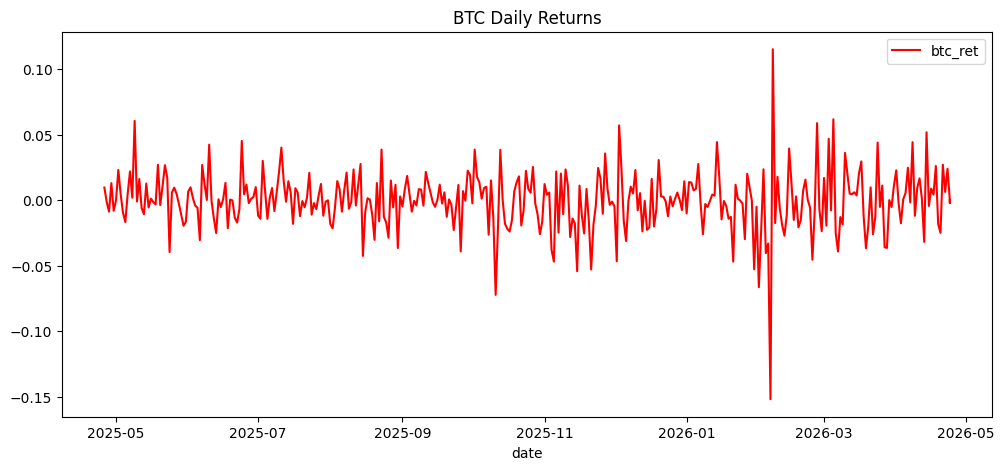

In [9]:
#plot prices
df.plot(x="date", y=["btc_ret"], figsize=(12, 5), title="BTC Daily Returns" ,color = ["red"])
plt.show()

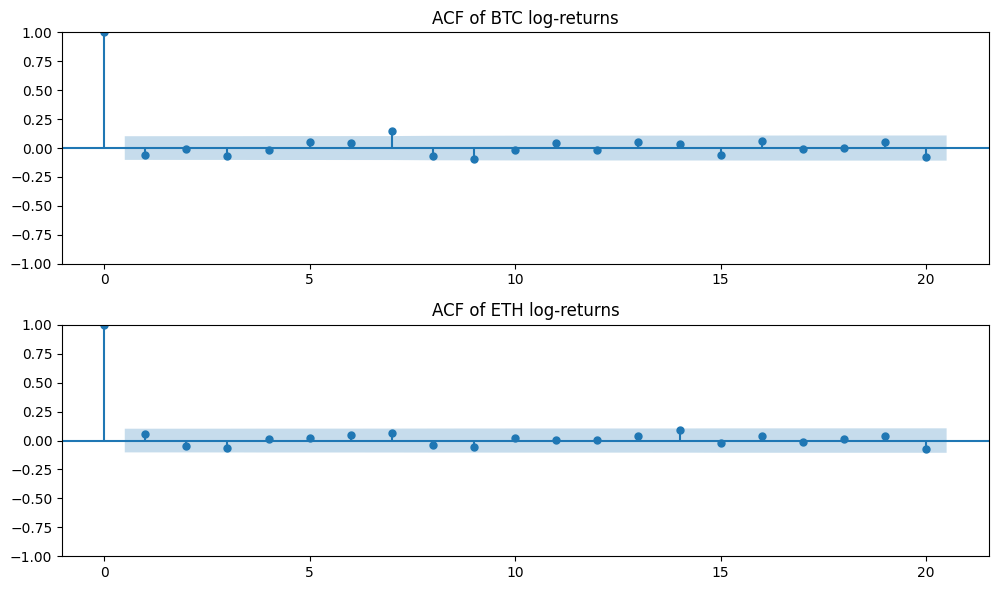

In [10]:
#acf plots to check for autocorrelation in returns

from statsmodels.graphics.tsaplots import plot_acf

fig, axes = plt.subplots(2, 1, figsize=(10, 6))
plot_acf(df["btc_ret"], ax=axes[0], lags=20)
axes[0].set_title("ACF of BTC log-returns")
plot_acf(df["eth_ret"], ax=axes[1], lags=20)
axes[1].set_title("ACF of ETH log-returns")
plt.tight_layout()
plt.show()

In [11]:
#check shape

x = df["btc_ret"].to_numpy()
y = df["eth_ret"].to_numpy()

print(x.shape, y.shape)

(367,) (367,)


In [12]:
#OLS regression of ETH returns on BTC returns, with robust standard errors
from scipy import stats

x = df["btc_ret"].to_numpy()
y = df["eth_ret"].to_numpy()

x_bar = np.mean(x)
y_bar = np.mean(y)

beta_hat = (np.sum((x - x_bar) * (y - y_bar)) / np.sum((x - x_bar) ** 2)).round(4)
alpha_hat = (y_bar - beta_hat * x_bar).round(4)

y_hat = alpha_hat + beta_hat * x
resid = y - y_hat

n = len(x)
k = 2
df_resid = n - k

# 95% confidence intervals using t‑critical from residuals d.f.
t_crit = stats.t.ppf(0.975, df_resid)

xm = x - x_bar
Sxx = np.sum(xm ** 2)

# robust variance of beta_hat
xmxu = xm * resid
v_beta = np.sum(xmxu ** 2) / Sxx
se_beta = np.sqrt(v_beta).round(6)

# robust variance of alpha_hat
v_alpha = np.sum(resid ** 2) / n + (x_bar ** 2) * v_beta
se_alpha = np.sqrt(v_alpha).round(6)


# Confidence intervals using robust SEs
ci_alpha = [alpha_hat - t_crit * se_alpha,
            alpha_hat + t_crit * se_alpha]

ci_beta = [(beta_hat - t_crit * se_beta).astype(float),
           (beta_hat + t_crit * se_beta).astype(float)]


lower_bounda = np.round(ci_alpha[0], 4)
upper_bounda = np.round(ci_alpha[1], 4)

lower_boundb = np.round(ci_beta[0], 4)
upper_boundb = np.round(ci_beta[1], 4)


print("alpha_hat:", alpha_hat)
print("beta_hat:", beta_hat)
print("SE(alpha):", se_alpha.round(4))
print("SE(beta):", se_beta.round(4))
print("95% CI alpha:" + '('+ str(lower_bounda) + ',' + str(upper_bounda) + ')')
print("95% CI beta:" + '('+ str(lower_boundb) + ',' + str(upper_boundb) + ')')


alpha_hat: 0.0014
beta_hat: 1.4098
SE(alpha): 0.02
SE(beta): 0.0308
95% CI alpha:(-0.038,0.0408)
95% CI beta:(1.3493,1.4703)


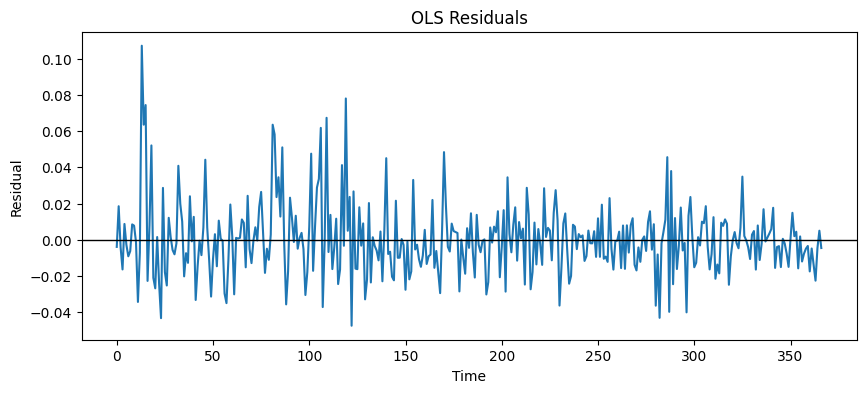

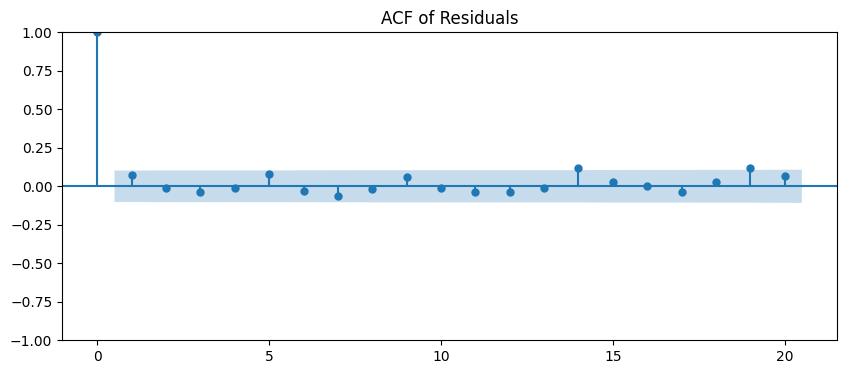

      lb_stat  lb_pvalue
10   8.522972   0.577892
20  22.965711   0.290481


In [13]:
# Residual diagnostics: plot residuals, ACF of residuals, and Ljung-Box test for autocorrelation
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox

# residual plot
plt.figure(figsize=(10, 4))
plt.plot(resid)
plt.axhline(0, color='black', linewidth=1)
plt.title('OLS Residuals')
plt.xlabel('Time')
plt.ylabel('Residual')
plt.show()

# ACF plot of residuals
fig, ax = plt.subplots(figsize=(10, 4))
plot_acf(resid, lags=20, ax=ax)
ax.set_title('ACF of Residuals')
plt.show()

# Ljung-Box test
lb = acorr_ljungbox(resid, lags=[10, 20], return_df=True)
print(lb)

GRADIENT DESCENT

In [ ]:
#Gradient Descent Implementation
#standardize features for gradient descent
x_mean = np.mean(x)
x_std = np.std(x)

y_mean = np.mean(y)
y_std = np.std(y)

x_gd = (x - x_mean) / x_std
y_gd = (y - y_mean) / y_std

In [ ]:
#MSE loss function for reproducibility
def mse_loss(alpha, beta, x, y):
    y_pred = alpha + beta * x
    return np.mean((y - y_pred) ** 2)

In [ ]:
#Gradient computation for OLS
def compute_gradients(alpha, beta, x, y):
    y_pred = alpha + beta * x
    error = y - y_pred
    
    grad_alpha = -2 * np.mean(error)
    grad_beta = -2 * np.mean(x * error)
    
    return grad_alpha, grad_beta

In [ ]:
#Gradient descent algorithm with paraameters for learning rate, max iterations, and convergence tolerance
def gradient_descent(x, y, alpha_init=0.0, beta_init=0.0, learning_rate=0.01, 
                     max_iter=10000, tol=1e-10):
    
    alpha = alpha_init
    beta = beta_init
    
    loss_history = []
    
    for i in range(max_iter):
        current_loss = mse_loss(alpha, beta, x, y)
        loss_history.append(current_loss)
        
        grad_alpha, grad_beta = compute_gradients(alpha, beta, x, y)
        
        new_alpha = alpha - learning_rate * grad_alpha
        new_beta = beta - learning_rate * grad_beta
        
        new_loss = mse_loss(new_alpha, new_beta, x, y)
        #convergence check
        if abs(current_loss - new_loss) < tol:
            alpha, beta = new_alpha, new_beta
            loss_history.append(new_loss)
            print(f"Converged after {i+1} iterations")
            return alpha, beta, loss_history
        
        alpha, beta = new_alpha, new_beta
    
    print("Maximum iterations reached")
    return alpha, beta, loss_history

In [ ]:
#Run gradient descent on standardised data
alpha_gd_std, beta_gd_std, loss_history = gradient_descent(
    x_gd, 
    y_gd,
    alpha_init=0.0,
    beta_init=0.0,
    learning_rate=0.01,
    max_iter=10000000,
    tol=1e-10
)

print("Gradient Descent estimates on standardised data")
print("alpha_gd_std:", round(alpha_gd_std, 6))
print("beta_gd_std:", round(beta_gd_std, 6))

Converged after 483 iterations
Gradient Descent estimates on standardised data
alpha_gd_std: 0.0
beta_gd_std: 0.843414


In [ ]:
#Transform gradient descent estimates back to original scale
beta_gd = beta_gd_std * (y_std / x_std)
alpha_gd = y_mean + y_std * alpha_gd_std - beta_gd * x_mean

print("Gradient Descent estimates on original scale")
print("alpha_gd:", round(alpha_gd, 6))
print("beta_gd:", round(beta_gd, 6))

Gradient Descent estimates on original scale
alpha_gd: 0.00145
beta_gd: 1.409678


In [ ]:
#display all results together
print("Analytical OLS estimates")
print("alpha_hat:", round(alpha_hat, 6))
print("beta_hat :", round(beta_hat, 6))

print("\nGradient Descent estimates")
print("alpha_gd :", round(alpha_gd, 6))
print("beta_gd  :", round(beta_gd, 6))

Analytical OLS estimates
alpha_hat: 0.0014
beta_hat : 1.4098

Gradient Descent estimates
alpha_gd : 0.00145
beta_gd  : 1.409678


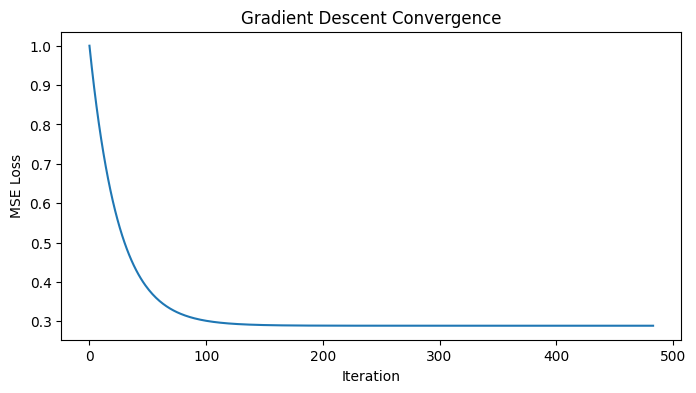

In [ ]:
#plot convergence of gradient descent for analysis
plt.figure(figsize=(8, 4))
plt.plot(loss_history)
plt.title("Gradient Descent Convergence")
plt.xlabel("Iteration")
plt.ylabel("MSE Loss")
plt.show()